# Lab 11 — Probing the Layers of BERT with SentEval Probing Tasks

**Introduction to LLM (AI463) · Lab Assignment 11**

**Question.** What linguistic information is *stored* in the sentence representation at each encoder layer of a BERT model? We answer it with **probing**: freeze the model, take the sentence representation from **one layer**, train a very simple classifier (**logistic regression**) on it, and look at the **test accuracy**. If a simple classifier can read a property from the vector, the property is (linearly) present in that layer.

| Task (file) | What must be predicted | Classes | Type of knowledge |
|---|---|---|---|
| **Sentence length** (`sentence_length.txt`) | length of the sentence, grouped into bins | 6 (labels 0–5) | *surface* |
| **Bigram shift** (`bigram_shift.txt`) | is the sentence intact (`O`) or were two adjacent words swapped (`I`)? | 2 | *syntactic* (legal word order) |
| **Subject number** (`subj_number.txt`) | is the subject of the main clause singular (`NN`) or plural (`NNS`)? | 2 | *semantic / morphosyntactic* |

### What this notebook does

1. Downloads the three SentEval probing files and builds, for **each task**, a **balanced 50 000-sentence dataset** (same number of sentences per class), split **90 : 10** into train / test, **keeping the class balance in both parts**.
2. Runs a BERT model once over all sentences and stores the **sentence vector of every layer** (mean over the word-piece vectors).
3. Trains **one logistic-regression model per layer per task** (12 layers → **12 models per task**, 36 in total) and evaluates each on the test set.
4. Compares the layers (tables, curves, best layer, comparison with the original probing paper) and explains the pattern.

> **About the paper link in the assignment.** arXiv 1803.05449 is the *SentEval toolkit* paper (it only lists the probing tasks as future work). The probing tasks and their **expected accuracies** are in *Conneau et al. 2018, "What you can cram into a single vector"* ([arXiv 1805.01070](https://arxiv.org/abs/1805.01070)); Section 6 below uses its Table 2 as the reference.

## 1. Setup

`%pip` installs into the environment this notebook's kernel uses. `numpy<2` keeps PyTorch 2.2 working. Restart the kernel after the first install.

In [1]:
# %pip install --quiet "numpy<2" torch "transformers>=4.40,<4.48" scikit-learn pandas matplotlib requests psutil jinja2

### 1.1 Configuration

| Setting | Meaning |
|---|---|
| `MODEL_NAME` | the BERT model that is probed. **`bert-base-uncased`** (12 layers → 12 probes per task) is the default. Lighter 12-layer alternative: `google/bert_uncased_L-12_H-256_A-4`; with a 6-layer model such as `distilbert-base-uncased` you get 6 probes per task (the notebook adapts automatically). |
| `N_PER_TASK` | number of sentences per task (50 000) |
| `POOLING` | how the token vectors of a layer are turned into **one sentence vector**: `"mean"` (average over all word-pieces, default) or `"cls"` (the `[CLS]` token vector) |
| `INCLUDE_EMBEDDING_LAYER` | also probe layer 0 (the input embeddings, before any transformer block) as a *baseline* — the 12 required models are layers 1 … 12 |
| `RANDOM_CONTROL` | also probe an **untrained (randomly initialised) BERT** as a control experiment (takes about as long again) |

In [2]:
import os, re, time, json, random, warnings
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel, AutoConfig
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ------------------------------- settings you may change -------------------------------
MODEL_NAME = os.environ.get("LAB11_MODEL", "bert-base-uncased")
N_PER_TASK = int(os.environ.get("LAB11_NTOTAL", 50_000))
TEST_FRACTION = 0.10
POOLING = "mean"                    # "mean" or "cls"
INCLUDE_EMBEDDING_LAYER = True      # layer 0 = baseline (not one of the 12 required models)
RANDOM_CONTROL = False              # also probe an untrained BERT
MAX_LEN = 64                        # sentences have 5-28 words -> well below 64 word-pieces
BATCH_SIZE = 128
LR_C = 1.0                          # inverse L2 regularisation strength of the logistic regression
LR_MAX_ITER = 300
DATA_DIR = os.environ.get("LAB11_DATA_DIR", "senteval_probing")
FEATURE_DIR = os.environ.get("LAB11_FEATURE_DIR", "probe_features")
# ----------------------------------------------------------------------------------------
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FEATURE_DIR, exist_ok=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
warnings.filterwarnings("ignore", category=ConvergenceWarning)

TASKS = {
    "sentence_length": "SentLen (sentence length, 6 classes)",
    "bigram_shift":    "BShift (bigram shift, 2 classes)",
    "subj_number":     "SubjNum (subject number, 2 classes)",
}
print(f"device = {device} | model = {MODEL_NAME} | {N_PER_TASK:,} sentences per task | pooling = {POOLING}")

device = mps | model = bert-base-uncased | 50,000 sentences per task | pooling = mean


## 2. Data — three SentEval probing tasks

Each file has one sentence per line in the format **`split <TAB> label <TAB> sentence`** (`split` ∈ `tr`, `va`, `te` is the original SentEval split; **we ignore it** and re-split ourselves as the assignment asks). Labels: sentence length `0…5`, bigram shift `O` / `I`, subject number `NN` / `NNS`.

### 2.1 Download

The files come from the SentEval GitHub repository (`data/probing/`). If your network blocks the download, save the three files from <https://github.com/facebookresearch/SentEval/tree/main/data/probing> into the folder `senteval_probing/`.

In [3]:
import requests

RAW_URL = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/{name}.txt"

def ensure_file(name):
    path = os.path.join(DATA_DIR, f"{name}.txt")
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"  [cached] {path}")
        return path
    url = RAW_URL.format(name=name)
    print(f"  downloading {url}")
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    with open(path, "wb") as f:
        f.write(r.content)
    print(f"    saved {len(r.content)/1e6:.1f} MB -> {path}")
    return path

def load_probing(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) == 3:
                rows.append(parts)
    return pd.DataFrame(rows, columns=["orig_split", "label", "sentence"])

raw = {}
for name in TASKS:
    raw[name] = load_probing(ensure_file(name))
    df = raw[name]
    print(f"{name:<16} {len(df):>7,} sentences | classes: {sorted(df.label.unique())} | per class: {df.label.value_counts().min():,}-{df.label.value_counts().max():,}")

  [cached] senteval_probing/sentence_length.txt
sentence_length  119,988 sentences | classes: ['0', '1', '2', '3', '4', '5'] | per class: 19,998-19,998
  [cached] senteval_probing/bigram_shift.txt
bigram_shift     120,000 sentences | classes: ['I', 'O'] | per class: 60,000-60,000
  [cached] senteval_probing/subj_number.txt
subj_number      120,000 sentences | classes: ['NN', 'NNS'] | per class: 60,000-60,000


### 2.2 Balanced 50 000-sentence datasets and a stratified 90 : 10 split

For each task:

1. **Pool** all sentences of the file (train + dev + test of the original split).
2. **Balance:** take the **same number of sentences from every class**: `50 000 // K` per class (K = number of classes), chosen at random with a fixed seed. Binary tasks → 25 000 + 25 000. Sentence length has **6 classes**, and 50 000 is not divisible by 6, so we take 8 333 per class = **49 998** sentences (the closest perfectly balanced size).
3. **Stratified split:** the 90 : 10 split is done **inside every class**, so train and test both keep the exact class balance.

In [4]:
def make_balanced(df, n_total, seed):
    classes = sorted(df.label.unique())
    per_class = n_total // len(classes)
    parts = []
    for c in classes:
        sub = df[df.label == c]
        assert len(sub) >= per_class, f"class {c} has only {len(sub)} sentences"
        parts.append(sub.sample(n=per_class, random_state=seed))
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True), per_class

def stratified_split(df, test_frac, seed):
    tr, te = [], []
    for c, sub in df.groupby("label"):
        sub = sub.sample(frac=1.0, random_state=seed)
        n_test = int(round(len(sub) * test_frac))
        te.append(sub.iloc[:n_test]); tr.append(sub.iloc[n_test:])
    train = pd.concat(tr).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    test = pd.concat(te).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return train, test

data = {}      # task -> dict(train=df, test=df, classes=[...])
for name in TASKS:
    balanced, per_class = make_balanced(raw[name], N_PER_TASK, SEED)
    train, test = stratified_split(balanced, TEST_FRACTION, SEED)
    data[name] = {"train": train, "test": test, "classes": sorted(balanced.label.unique())}
    print(f"{name:<16} {len(balanced):>6,} sentences ({per_class:,} per class)  ->  train {len(train):>6,} | test {len(test):>5,}")

# class-balance check
for name, d in data.items():
    tab = pd.DataFrame({"train": d["train"].label.value_counts(), "test": d["test"].label.value_counts()}).loc[d["classes"]]
    tab["train %"] = (100 * tab["train"] / tab["train"].sum()).round(2)
    tab["test %"] = (100 * tab["test"] / tab["test"].sum()).round(2)
    print(f"\n{name}: class balance")
    display(tab)

sentence_length  49,998 sentences (8,333 per class)  ->  train 45,000 | test 4,998
bigram_shift     50,000 sentences (25,000 per class)  ->  train 45,000 | test 5,000
subj_number      50,000 sentences (25,000 per class)  ->  train 45,000 | test 5,000

sentence_length: class balance


,train,test,train %,test %
label,,,,
0,7500,833,16.67,16.67
1,7500,833,16.67,16.67
2,7500,833,16.67,16.67
3,7500,833,16.67,16.67
4,7500,833,16.67,16.67
5,7500,833,16.67,16.67



bigram_shift: class balance


,train,test,train %,test %
label,,,,
I,22500,2500,50.0,50.0
O,22500,2500,50.0,50.0



subj_number: class balance


,train,test,train %,test %
label,,,,
NN,22500,2500,50.0,50.0
NNS,22500,2500,50.0,50.0


In [5]:
# what do the classes look like?
for name, d in data.items():
    print(f"\n=== {TASKS[name]} ===")
    for c in d["classes"]:
        ex = d["train"][d["train"].label == c].sentence.iloc[0]
        print(f"  label {c:<4}: {ex[:110]}")

sl = data["sentence_length"]["train"].copy()
sl["words"] = sl.sentence.str.split().str.len()
print("\nSentence-length classes: number of words per class (the bins used by SentEval):")
display(sl.groupby("label")["words"].agg(["min", "max", "mean"]).round(1))

# leakage check: sentences that occur in both train and test
for name, d in data.items():
    dup = len(set(d["train"].sentence) & set(d["test"].sentence))
    print(f"{name:<16} sentences present in both train and test: {dup}")


=== SentLen (sentence length, 6 classes) ===
  label 0   : But he said he was prepared !
  label 1   : Without his habitual smile he seemed cold and unfriendly .
  label 2   : He 's talking to the rest of our Councils as we speak . '
  label 3   : Do you think that stupid get my daughter married was going to go looking for your horse ?
  label 4   : A few were high stars , guiding lights from beyond the circle of the sea that led the People in a grander sens
  label 5   : " I put some of my antidotes in darts just in case poisons go too far in for it to enter the body through the 

=== BShift (bigram shift, 2 classes) ===
  label I   : The moment he was finished he erased their memories and left the three of sitting them comfortably inside the 
  label O   : The customers in the store froze .

=== SubjNum (subject number, 2 classes) ===
  label NN  : Carved and polished paneling lined all the interior walls .
  label NNS : The networks could find patterns in data better than the human

,min,max,mean
label,,,
0,5,8,6.6
1,9,12,10.4
2,13,16,14.4
3,17,20,18.4
4,21,25,22.8
5,26,28,26.9


sentence_length  sentences present in both train and test: 38
bigram_shift     sentences present in both train and test: 10
subj_number      sentences present in both train and test: 26


## 3. Sentence representations from every BERT layer

### 3.1 Idea

`BertModel(..., output_hidden_states=True)` returns **13 tensors**: the output of the embedding layer ($h^{(0)}$) and the outputs of the 12 transformer blocks ($h^{(1)},\dots,h^{(12)}$), each of shape *(sentence length in word-pieces) × 768*. Block $\ell$ computes

$$h^{(\ell)}=\text{Block}_\ell\big(h^{(\ell-1)}\big)$$

(self-attention + feed-forward, each with residual connection and layer norm), so higher layers mix more context. To get **one vector per sentence** we pool the token vectors of one layer — with the default **mean pooling** over the $T$ real tokens (padding is ignored):

$$s^{(\ell)}=\frac1T\sum_{t=1}^{T}h^{(\ell)}_t\;\in\mathbb R^{768}$$

(with `POOLING = "cls"` it is simply $s^{(\ell)}=h^{(\ell)}_{[CLS]}$). The BERT weights are **frozen** — we only run forward passes, once, and keep the 13 vectors of every sentence (stored as 16-bit numbers in `probe_features/` so a restart does not repeat the work).

### 3.2 Load the model

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
cfg = AutoConfig.from_pretrained(MODEL_NAME)
N_LAYERS = cfg.num_hidden_layers
HIDDEN = cfg.hidden_size
print(f"{MODEL_NAME}: {N_LAYERS} transformer layers, hidden size {HIDDEN}  ->  {N_LAYERS} probes (layers 1..{N_LAYERS}) per task"
      + (" + layer-0 baseline" if INCLUDE_EMBEDDING_LAYER else ""))

def load_encoder(random_init=False):
    m = AutoModel.from_config(cfg) if random_init else AutoModel.from_pretrained(MODEL_NAME)
    return m.eval().to(device)

# peek at one sentence
ex = data["bigram_shift"]["train"].sentence.iloc[0]
print("\nexample:", ex)
print("word-pieces:", tokenizer.tokenize(ex))

bert-base-uncased: 12 transformer layers, hidden size 768  ->  12 probes (layers 1..12) per task + layer-0 baseline

example: The customers in the store froze .
word-pieces: ['the', 'customers', 'in', 'the', 'store', 'froze', '.']


### 3.3 Extract the features (one pass over all sentences of a task)

Sentences are sorted by length and batched, so very little padding is processed. The result for a task is an array of shape *(number of sentences, 13, 768)* in 16-bit floats. Progress is printed.

In [7]:
PAD_ID = tokenizer.pad_token_id

@torch.inference_mode()
def extract_features(model, sentences, batch_size=BATCH_SIZE):
    ids = tokenizer(list(sentences), truncation=True, max_length=MAX_LEN)["input_ids"]
    order = np.argsort([len(x) for x in ids], kind="stable")
    out, t0 = None, time.time()
    n_batches = (len(order) + batch_size - 1) // batch_size
    for b, s in enumerate(range(0, len(order), batch_size)):
        idx = order[s:s + batch_size]
        batch = [ids[i] for i in idx]
        maxlen = max(len(x) for x in batch)
        inp = torch.full((len(batch), maxlen), PAD_ID, dtype=torch.long)
        mask = torch.zeros((len(batch), maxlen), dtype=torch.long)
        for r, x in enumerate(batch):
            inp[r, :len(x)] = torch.tensor(x); mask[r, :len(x)] = 1
        inp, mask = inp.to(device), mask.to(device)
        hs = model(input_ids=inp, attention_mask=mask, output_hidden_states=True).hidden_states   # (L+1) x [B, T, H]
        stack = torch.stack(hs, dim=1)                                  # [B, L+1, T, H]
        if POOLING == "cls":
            pooled = stack[:, :, 0, :]
        else:
            m = mask[:, None, :, None].to(stack.dtype)
            pooled = (stack * m).sum(dim=2) / m.sum(dim=2)              # mean over real tokens
        arr = pooled.float().cpu().numpy().astype(np.float16)
        if out is None:
            out = np.zeros((len(order), arr.shape[1], arr.shape[2]), dtype=np.float16)
        out[idx] = arr
        if (b + 1) % 50 == 0 or b + 1 == n_batches:
            print(f"      batch {b + 1}/{n_batches}  ({time.time() - t0:.0f}s)")
    return out

def get_features(model, variant, task):
    """Features for the train and test sentences of a task (cached on disk)."""
    path = os.path.join(FEATURE_DIR, f"{variant}_{task}_{POOLING}_{N_PER_TASK}.npz")
    d = data[task]
    if os.path.exists(path):
        z = np.load(path)
        if z["train"].shape[0] == len(d["train"]) and z["test"].shape[0] == len(d["test"]):
            print(f"   [cached] {path}")
            return z["train"], z["test"]
    sentences = list(d["train"].sentence) + list(d["test"].sentence)
    feats = extract_features(model, sentences)
    n_tr = len(d["train"])
    np.savez(path, train=feats[:n_tr], test=feats[n_tr:])
    return feats[:n_tr], feats[n_tr:]

## 4. The probes — logistic regression on each layer

For a fixed task and layer $\ell$ we train a **multinomial logistic regression** on the sentence vectors $s^{(\ell)}$:

$$P(y=k\mid s)=\frac{\exp(w_k^{\top}s+b_k)}{\sum_{j=1}^{K}\exp(w_j^{\top}s+b_j)},\qquad \mathcal L(W,b)=-\sum_{i}\log P(y_i\mid s_i)+\frac{1}{2C}\lVert W\rVert_2^2$$

* $K=6$ for sentence length, $K=2$ for bigram shift and subject number.
* The classifier is **linear** on purpose: it cannot compute new features, so its accuracy measures how much of the property is *already readable* from the layer. (The paper used an MLP; a linear probe is a stricter test.)
* $C$ (`LR_C = 1`) controls the L2 regularisation. Features are **standardised** (zero mean, unit variance, statistics from the *training* part only) because some BERT dimensions have huge scales, which would slow down the optimiser.
* **12 layers × 3 tasks = 36 models.** The metric is **accuracy on the held-out 10 % test set** (balanced, so the majority-class baseline is 100/K %: 16.7 % for sentence length, 50 % for the other two).

In [8]:
def fit_probe(X_tr, y_tr, X_te, y_te):
    X_tr, X_te = X_tr.astype(np.float32), X_te.astype(np.float32)
    scaler = StandardScaler().fit(X_tr)
    clf = LogisticRegression(C=LR_C, max_iter=LR_MAX_ITER)
    t0 = time.time()
    clf.fit(scaler.transform(X_tr), y_tr)
    return {"train_acc": clf.score(scaler.transform(X_tr), y_tr),
            "test_acc": clf.score(scaler.transform(X_te), y_te),
            "n_iter": int(np.max(clf.n_iter_)), "secs": time.time() - t0}, clf, scaler

variants = ["pretrained"] + (["random"] if RANDOM_CONTROL else [])
first_layer = 0 if INCLUDE_EMBEDDING_LAYER else 1
results, probes_store = [], {}
RESULTS_PATH = os.path.join(FEATURE_DIR, "probe_results_partial.csv")

### 4.1 Run everything

For each task: extract the features (once), then train and test one logistic regression for every layer. Layer 0 is the embedding baseline, layers 1 … N are the probes asked for in the assignment. The first run needs a while (BERT forward passes for ~150 000 sentences + 36–39 logistic regressions); the cell prints progress and the intermediate results are saved. *Rough expectation (not measured on your machine): about 5–20 minutes for the BERT passes on an Apple-silicon Mac or GPU, plus 15–40 minutes for the logistic regressions; a CPU-only machine is several times slower — then lower `N_PER_TASK`.*

In [9]:
t_all = time.time()
for variant in variants:
    model = load_encoder(random_init=(variant == "random"))
    for task in TASKS:
        print(f"\n### {variant} BERT | {TASKS[task]}")
        d = data[task]
        label2id = {c: i for i, c in enumerate(d["classes"])}
        y_tr = d["train"].label.map(label2id).values
        y_te = d["test"].label.map(label2id).values
        F_tr, F_te = get_features(model, variant, task)          # [N, L+1, H]
        for layer in range(first_layer, N_LAYERS + 1):
            res, clf, scaler = fit_probe(F_tr[:, layer, :], y_tr, F_te[:, layer, :], y_te)
            results.append({"variant": variant, "task": task, "layer": layer, **res})
            print(f"   layer {layer:>2}: train acc {res['train_acc']:.4f} | TEST acc {res['test_acc']:.4f} | {res['n_iter']} iters, {res['secs']:.1f}s")
            if variant == "pretrained":
                probes_store[(task, layer)] = (clf, scaler)
        pd.DataFrame(results).to_csv(RESULTS_PATH, index=False)
    del model
print(f"\nAll probes finished in {(time.time() - t_all) / 60:.1f} min")
results_df = pd.DataFrame(results)
results_df.to_csv("probing_results.csv", index=False)


### pretrained BERT | SentLen (sentence length, 6 classes)
   [cached] probe_features/pretrained_sentence_length_mean_50000.npz
   layer  0: train acc 0.9970 | TEST acc 0.9624 | 185 iters, 7.6s
   layer  1: train acc 0.9939 | TEST acc 0.9574 | 191 iters, 7.3s
   layer  2: train acc 0.9900 | TEST acc 0.9564 | 214 iters, 16.5s
   layer  3: train acc 0.9898 | TEST acc 0.9586 | 210 iters, 10.0s
   layer  4: train acc 0.9840 | TEST acc 0.9502 | 280 iters, 9.3s
   layer  5: train acc 0.9794 | TEST acc 0.9412 | 263 iters, 12.2s
   layer  6: train acc 0.9702 | TEST acc 0.9326 | 284 iters, 17.9s
   layer  7: train acc 0.9605 | TEST acc 0.9146 | 291 iters, 12.2s
   layer  8: train acc 0.9529 | TEST acc 0.9056 | 294 iters, 9.1s


KeyboardInterrupt: 

## 5. Results

### 5.1 Test accuracy of the 12 models per task

Rows = layers (0 = embedding baseline, 1 … 12 = the required models), columns = tasks. The **best layer** of every task is highlighted.

In [ ]:
pre = results_df[results_df.variant == "pretrained"]
acc = pre.pivot(index="layer", columns="task", values="test_acc")[list(TASKS)]
acc.columns = [TASKS[t].split(" (")[0] for t in acc.columns]

baseline = pd.Series({TASKS[t].split(" (")[0]: 1.0 / len(data[t]["classes"]) for t in TASKS})
try:
    display((100 * acc).round(2).style.highlight_max(axis=0, color="#bbf7d0").format("{:.2f}"))
except ImportError:                      # Styler needs jinja2; fall back to a plain table
    display((100 * acc).round(2))
print("Majority-class baseline (%):", (100 * baseline).round(1).to_dict())

best = pd.DataFrame({"best layer": acc.idxmax(), "best test acc %": (100 * acc.max()).round(2),
                     "baseline %": (100 * baseline).round(1), "gain over baseline (pts)": (100 * (acc.max() - baseline)).round(2)})
print("\nBest layer per task:")
display(best)

,SentLen,BShift,SubjNum
layer,,,
0,96.24,49.02,83.24
1,95.74,56.90,84.28
2,95.64,69.60,84.68
3,95.86,83.28,85.24
4,95.02,85.46,85.76
5,94.12,87.48,87.60
6,93.26,88.36,87.84
7,91.46,89.42,88.60
8,90.56,90.06,87.72


Majority-class baseline (%): {'SentLen': 16.7, 'BShift': 50.0, 'SubjNum': 50.0}

Best layer per task:


,best layer,best test acc %,baseline %,gain over baseline (pts)
SentLen,0,96.24,16.7,79.57
BShift,9,90.20,50.0,40.20
SubjNum,7,88.60,50.0,38.60


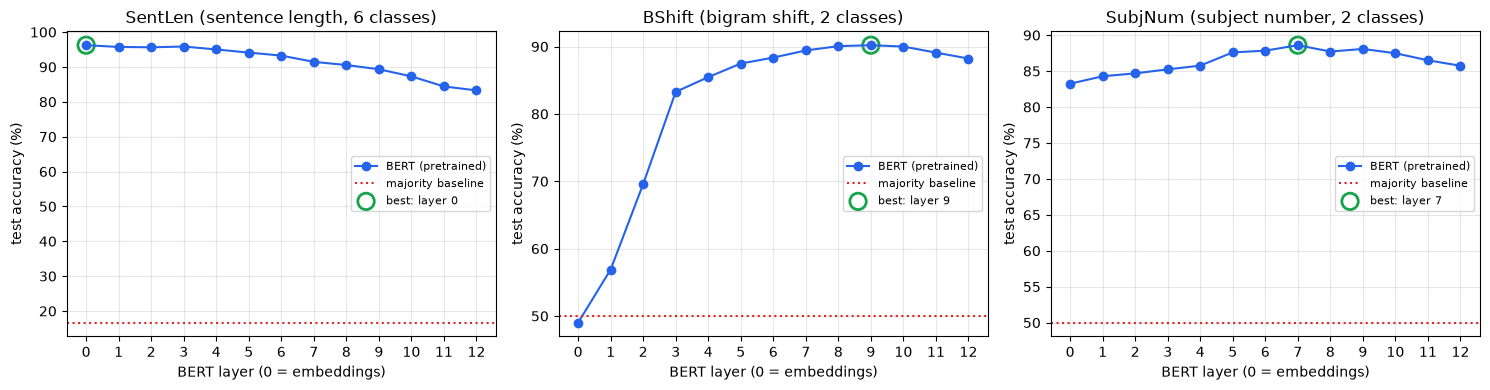

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, task in zip(axes, TASKS):
    short = TASKS[task].split(" (")[0]
    ax.plot(acc.index, 100 * acc[short], "o-", color="#2563eb", label="BERT (pretrained)")
    if RANDOM_CONTROL:
        rnd = results_df[(results_df.variant == "random") & (results_df.task == task)].set_index("layer")["test_acc"]
        ax.plot(rnd.index, 100 * rnd, "s--", color="#9ca3af", label="BERT (random init)")
    ax.axhline(100 * baseline[short], color="#dc2626", ls=":", label="majority baseline")
    bl = acc[short].idxmax()
    ax.scatter([bl], [100 * acc[short].max()], s=140, facecolors="none", edgecolors="#16a34a", linewidths=2, label=f"best: layer {bl}")
    ax.set_title(TASKS[task]); ax.set_xlabel("BERT layer (0 = embeddings)"); ax.set_ylabel("test accuracy (%)")
    ax.set_xticks(list(acc.index)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Train vs. test accuracy and how hard the optimiser had to work

A large gap between train and test accuracy means the probe over-fits (many features, few examples); `n_iter` close to `LR_MAX_ITER` means the optimiser had not fully converged (accuracy can then be slightly under-estimated).

In [ ]:
gap = pre.assign(gap=pre.train_acc - pre.test_acc).pivot(index="layer", columns="task", values="gap")[list(TASKS)]
gap.columns = acc.columns
print("train accuracy - test accuracy (percentage points):")
display((100 * gap).round(2))
its = pre.pivot(index="layer", columns="task", values="n_iter")[list(TASKS)]
its.columns = acc.columns
print("optimiser iterations (limit = %d):" % LR_MAX_ITER)
display(its)

train accuracy - test accuracy (percentage points):


,SentLen,BShift,SubjNum
layer,,,
0,3.46,6.21,1.67
1,3.65,3.13,1.28
2,3.36,3.13,1.15
3,3.13,0.93,1.18
4,3.38,2.06,1.26
5,3.82,1.51,1.10
6,3.76,1.84,1.08
7,4.59,1.88,1.02
8,4.73,1.88,1.42


optimiser iterations (limit = 300):


,SentLen,BShift,SubjNum
layer,,,
0,185,87,85
1,191,128,103
2,214,97,86
3,210,85,93
4,280,93,101
5,263,74,117
6,284,72,104
7,291,75,93
8,294,73,77


### 5.3 Automatic summary — which layers carry which information?

The cell reads the table and describes, per task, where the information is strongest (lower / middle / upper layers) and how much the best layer improves over the first and the last layer.

In [ ]:
def region(layer, n=N_LAYERS):
    if layer <= n / 3: return "LOWER layers"
    if layer <= 2 * n / 3: return "MIDDLE layers"
    return "UPPER layers"

for task in TASKS:
    short = TASKS[task].split(" (")[0]
    s = acc[short]
    bl = int(s.idxmax())
    lo = s.loc[first_layer if first_layer > 0 else 1]
    print(f"{TASKS[task]}")
    print(f"   best layer {bl} ({region(bl)}): {100*s.max():.2f}%  |  layer 1: {100*s.loc[1]:.2f}%  |  last layer {N_LAYERS}: {100*s.loc[N_LAYERS]:.2f}%  |  baseline {100*baseline[short]:.1f}%")
    trend = "falls" if s.loc[N_LAYERS] < s.loc[1] - 0.005 else ("rises" if s.loc[N_LAYERS] > s.loc[1] + 0.005 else "stays flat")
    print(f"   from layer 1 to layer {N_LAYERS} the accuracy {trend} ({100*(s.loc[N_LAYERS]-s.loc[1]):+.2f} points)\n")

SentLen (sentence length, 6 classes)
   best layer 0 (LOWER layers): 96.24%  |  layer 1: 95.74%  |  last layer 12: 83.27%  |  baseline 16.7%
   from layer 1 to layer 12 the accuracy falls (-12.46 points)

BShift (bigram shift, 2 classes)
   best layer 9 (UPPER layers): 90.20%  |  layer 1: 56.90%  |  last layer 12: 88.22%  |  baseline 50.0%
   from layer 1 to layer 12 the accuracy rises (+31.32 points)

SubjNum (subject number, 2 classes)
   best layer 7 (MIDDLE layers): 88.60%  |  layer 1: 84.28%  |  last layer 12: 85.74%  |  baseline 50.0%
   from layer 1 to layer 12 the accuracy rises (+1.46 points)



### 5.4 Where does the sentence-length probe go wrong?

Confusion matrix of the best sentence-length layer on the test set. Lengths are ordered bins, so errors should mostly be to the **neighbouring** bin.

In [ ]:
task = "sentence_length"
best_layer = int(acc["SentLen"].idxmax())
clf, scaler = probes_store[(task, best_layer)]
d = data[task]
label2id = {c: i for i, c in enumerate(d["classes"])}
_, F_te = get_features(None, "pretrained", task)
y_te = d["test"].label.map(label2id).values
pred = clf.predict(scaler.transform(F_te[:, best_layer, :].astype(np.float32)))
cm = np.zeros((len(d["classes"]),) * 2, dtype=int)
for t, p in zip(y_te, pred):
    cm[t, p] += 1
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in d["classes"]], columns=[f"pred {c}" for c in d["classes"]])
print(f"Sentence-length probe on layer {best_layer}: confusion matrix (test set)")
display(cm_df)
near = sum(cm[i, j] for i in range(cm.shape[0]) for j in range(cm.shape[1]) if abs(i - j) <= 1) / cm.sum()
print(f"share of test sentences predicted in the correct bin or the neighbouring bin: {100 * near:.1f}%")

   [cached] probe_features/pretrained_sentence_length_mean_50000.npz
Sentence-length probe on layer 0: confusion matrix (test set)


,pred 0,pred 1,pred 2,pred 3,pred 4,pred 5
true 0,815,18,0,0,0,0
true 1,13,800,20,0,0,0
true 2,2,13,801,17,0,0
true 3,0,0,25,787,21,0
true 4,0,0,0,17,794,22
true 5,0,0,0,0,20,813


share of test sentences predicted in the correct bin or the neighbouring bin: 100.0%


## 6. Comparison with the original probing paper

Conneau et al. (2018, [arXiv 1805.01070](https://arxiv.org/abs/1805.01070)), **Table 2**, test accuracy (%) with an **MLP** probe on the *final* sentence vector of several sentence encoders (different models and a different probe, so compare **trends**, not exact values). SentLen is the 6-way length task, BShift and SubjNum are binary.

| Model | SentLen | BShift | SubjNum |
|---|---|---|---|
| Majority vote | 20.0 | 50.0 | 50.0 |
| Human evaluation | 100 | 98.0 | 88.0 |
| BoV-fastText | 66.6 | 50.8 | 82.1 |
| BiLSTM-max, untrained | 73.3 | 70.6 | 85.8 |
| BiLSTM-max, NMT En-Fr | 80.1 | 73.7 | 90.3 |
| BiLSTM-max, Seq2Tree | 93.3 | 82.1 | 95.1 |
| BiLSTM-max, SkipThought | 66.0 | 73.8 | 85.0 |
| BiLSTM-max, NLI | 71.7 | 65.1 | 80.7 |
| GatedConvNet, untrained | 90.3 | 62.0 | 72.2 |

(The paper's majority vote for SentLen is 20 % because its bins are not exactly equal in size; ours is a perfectly balanced 6-class set, so the baseline is 16.7 %.)

In [ ]:
paper = pd.DataFrame({
    "Model": ["Majority vote", "Human evaluation", "BoV-fastText", "BiLSTM-max untrained", "BiLSTM-max NMT En-Fr", "BiLSTM-max Seq2Tree",
              "BiLSTM-max SkipThought", "BiLSTM-max NLI", "GatedConvNet untrained"],
    "SentLen": [20.0, 100, 66.6, 73.3, 80.1, 93.3, 66.0, 71.7, 90.3],
    "BShift":  [50.0, 98.0, 50.8, 70.6, 73.7, 82.1, 73.8, 65.1, 62.0],
    "SubjNum": [50.0, 88.0, 82.1, 85.8, 90.3, 95.1, 85.0, 80.7, 72.2],
}).set_index("Model")

ours = pd.DataFrame({
    "SentLen": [100 * acc["SentLen"].max(), 100 * acc["SentLen"].loc[N_LAYERS]],
    "BShift":  [100 * acc["BShift"].max(),  100 * acc["BShift"].loc[N_LAYERS]],
    "SubjNum": [100 * acc["SubjNum"].max(), 100 * acc["SubjNum"].loc[N_LAYERS]],
}, index=[f"{MODEL_NAME}: BEST layer (linear probe)", f"{MODEL_NAME}: LAST layer (linear probe)"]).round(1)
display(pd.concat([paper, ours]))

,SentLen,BShift,SubjNum
Majority vote,20.0,50.0,50.0
Human evaluation,100.0,98.0,88.0
BoV-fastText,66.6,50.8,82.1
BiLSTM-max untrained,73.3,70.6,85.8
BiLSTM-max NMT En-Fr,80.1,73.7,90.3
BiLSTM-max Seq2Tree,93.3,82.1,95.1
BiLSTM-max SkipThought,66.0,73.8,85.0
BiLSTM-max NLI,71.7,65.1,80.7
GatedConvNet untrained,90.3,62.0,72.2
bert-base-uncased: BEST layer (linear probe),96.2,90.2,88.6


## 7. Discussion (template — replace the *italics* with what **your** tables and curves show)

What to look at, and the pattern usually reported for BERT-style encoders (verify each statement against **your** numbers before writing it — e.g. layer-wise probing of BERT in the literature such as Jawahar et al., 2019, finds *surface → syntactic → semantic* information from lower to upper layers):

1. **Sentence length (surface).** *Expected: high accuracy already in the lowest layers, then **decreasing** with depth — position/length information is strongest close to the input and is gradually replaced by more abstract features.* State your best layer and the drop to the last layer.
2. **Bigram shift (syntactic).** *Expected: close to the 50 % baseline at the embedding layer (a bag of word vectors cannot see word order), then **rising sharply in the lower-middle layers** (self-attention builds order/syntax information), and often declining slightly in the top layers.* Which layer is the peak in your run?
3. **Subject number (semantic / morphosyntactic).** *Expected: already well above chance in the lowest layers (plural nouns are visible lexically: "dogs"), improving and peaking in the **middle-to-upper layers** where the model has linked the subject to the verb.* Compare with the plateau value.
4. **Layer 0 (embeddings) and the random-init control.** *Layer 0 shows how much is readable from the words alone; if `RANDOM_CONTROL` was run, the gap between the pretrained and random curves is what **pre-training** added.*
5. **Linear probe vs. paper.** *The paper used an MLP on trained encoders; a linear probe on frozen BERT layers may be lower for BShift (order information is not linearly separable from mean-pooled vectors) — comment on this.*
6. **Caveats.** *Probe accuracy shows that information is **available**, not that BERT **uses** it. Mean pooling discards token order; `[CLS]` pooling would change the picture; one random split and one seed; accuracy differences of a fraction of a point are within noise (test size 5 000 / 833 per class → standard error ≈ 0.6 points).*

## 8. Troubleshooting

| Symptom | Fix |
|---|---|
| Download blocked / `404` | download the three files from the SentEval GitHub page into `senteval_probing/` |
| Feature extraction slow | uses Apple-silicon (MPS) / GPU automatically; on CPU it takes longer — use `N_PER_TASK = 20000`, or a lighter model such as `google/bert_uncased_L-12_H-256_A-4`, or run on Colab / Kaggle |
| Out of memory during extraction | lower `BATCH_SIZE` (e.g. 32) |
| Logistic regression slow / `n_iter` hits the limit | lower `LR_MAX_ITER`, or raise regularisation (`LR_C = 0.1`) |
| Restart and re-run | features are cached in `probe_features/`, so only the (fast) probe training is repeated |
| numpy / torch import errors | `%pip install "numpy<2"` and restart the kernel |

In [ ]:
# save the final tables
acc.round(4).to_csv("probing_accuracy_by_layer.csv")
best.to_csv("probing_best_layers.csv")
print("Saved: probing_results.csv, probing_accuracy_by_layer.csv, probing_best_layers.csv")

Saved: probing_results.csv, probing_accuracy_by_layer.csv, probing_best_layers.csv
